# Stokes: the BBTD board

This tutorial decomposes the polarization image from [Tensors in plain words](../getting-started/tensors.ipynb):
160 × 160 pixels showing the letters **B B T D**. Each letter and the background has one
polarization state:

| region | polarization (S1, S2, S3) |
|---|---|
| first B | horizontal linear (1, 0, 0) |
| second B | linear at +45° (0, 1, 0) |
| T | circular (0, 0, 1) |
| D | linear at −45° (0, −1, 0) |
| background | circular, opposite handedness (0, 0, −1) |

The intensity S0 is random, between 0.5 and 1.

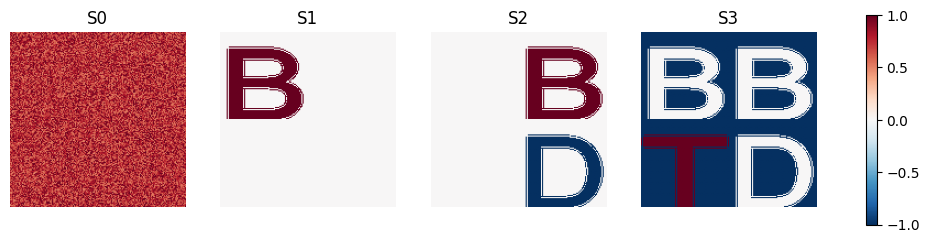

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from pybbtd import Stokes
from pybbtd.datasets import load_bbtd_board
from pybbtd.stokes import validate_stokes_tensor
from pybbtd.visualization import plot_error, plot_stokes_terms

np.random.seed(0)
T = load_bbtd_board()

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for k, ax in enumerate(axes):
    im = ax.imshow(T[:, :, k], cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"S{k}")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

Since S0 is below 1 while the polarized part (S1, S2, S3) always has length 1, no pixel is
a physically valid Stokes vector:

In [2]:
validate_stokes_tensor(T)

  validate_stokes_tensor(T)


False

The model still recovers the five states, because it forces the Stokes vector of each term
to be valid.

## Fit the model

R = 5 terms (four letters and the background). The letters have more complex shapes than
blobs, so the spatial maps get a higher rank, L = 25.

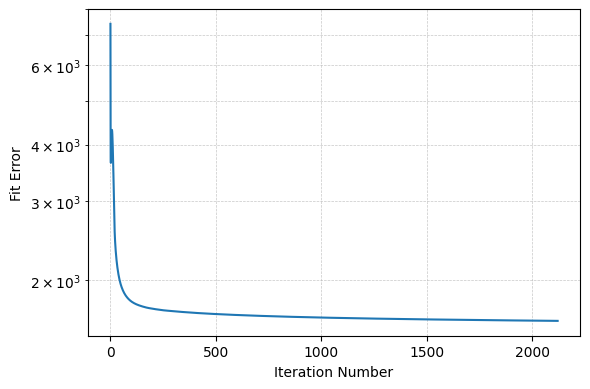

In [3]:
model = Stokes(T.shape[:2], R=5, L=25)
model.fit(
    T,
    init="kmeans",
    max_iter=5000,
    max_admm=2,
    rel_tol=1e-5,
    abs_tol=1e-7,
    admm_tol=1e-5,
)
plot_error(model.fit_error)

## Results

Each column is one term: its spatial map, and the ellipse traced by the electric field
for its polarization. ψ is the orientation of the ellipse, χ its ellipticity (0° for
linear, ±45° for circular), and LH/RH the handedness given by the sign of S3.

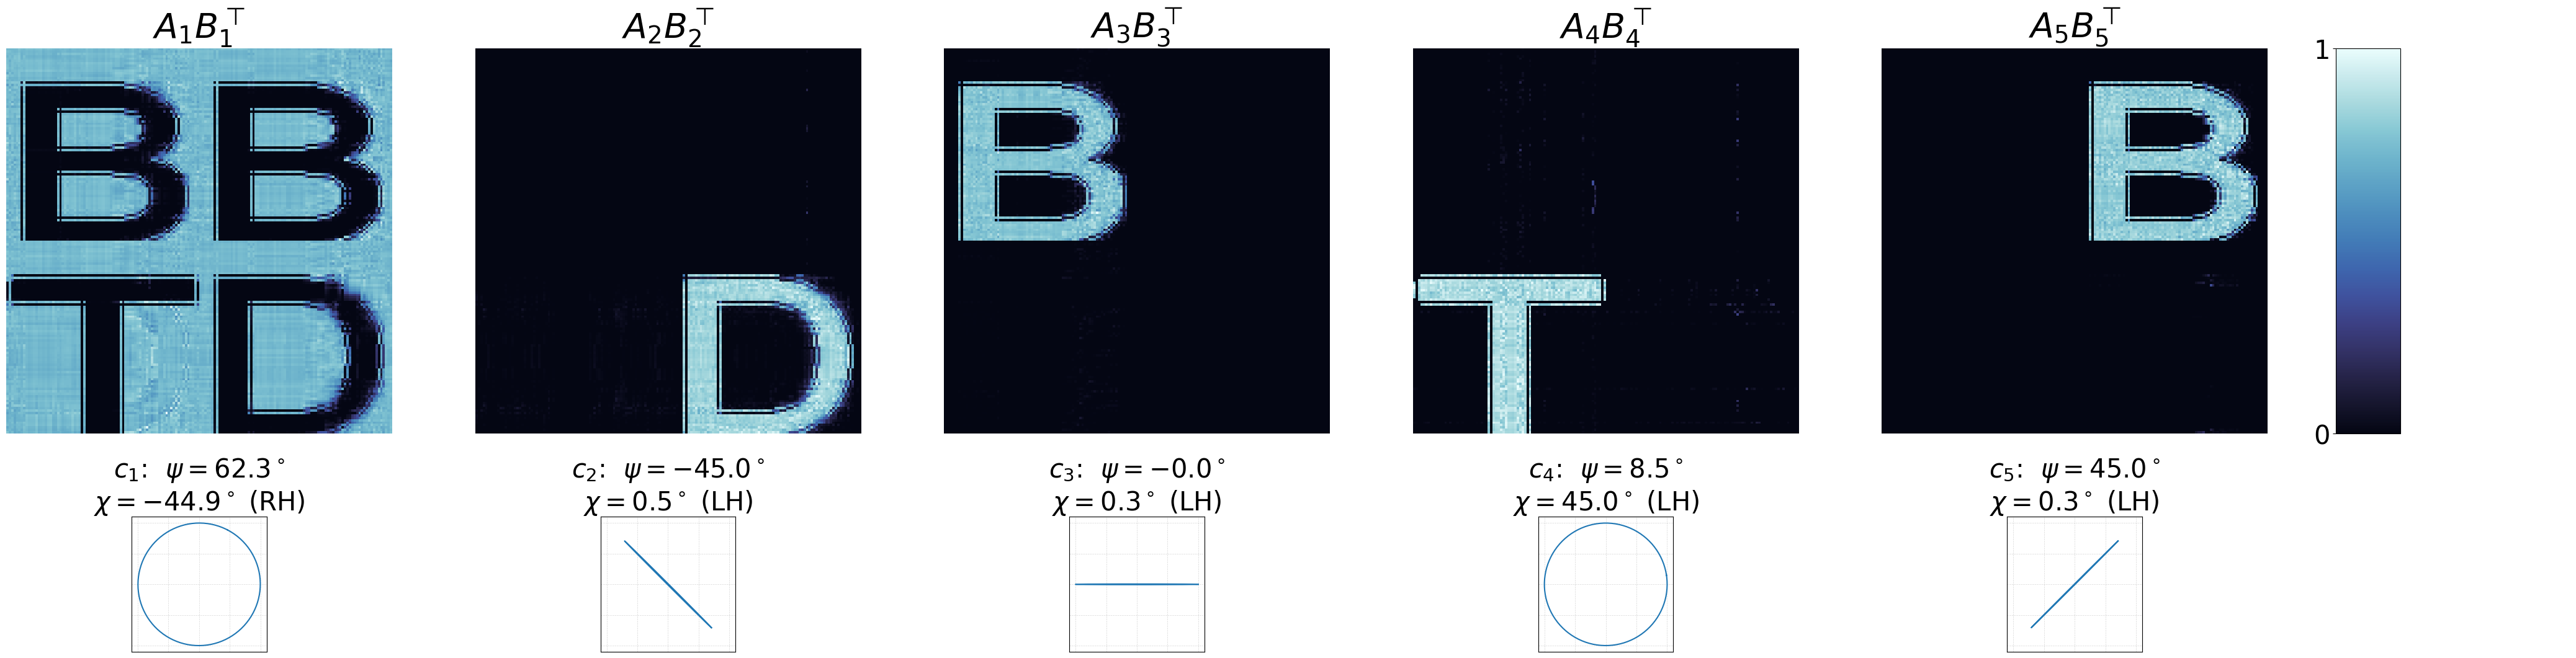

In [4]:
A, B, C = model.factors
plot_stokes_terms(A, B, C, R=5, L=25)

The recovered Stokes vectors, scaled to S0 = 1, are the five states of the table above:

In [5]:
np.set_printoptions(precision=3, suppress=True)
C / C[0]

array([[ 1.   ,  1.   ,  1.   ,  1.   ,  1.   ],
       [-0.003,  0.   ,  1.   ,  0.001,  0.   ],
       [ 0.004, -1.   , -0.   ,  0.   ,  1.   ],
       [-1.   ,  0.016,  0.011,  1.   ,  0.011]])

The remaining fit error comes from the random intensity S0, which these five terms
describe only approximately:

In [6]:
np.linalg.norm(model.tensor - T) / np.linalg.norm(T)

np.float64(0.20030134210128397)